### IMPORTANT NOTE
The analytical results presented in this paper are derived from the full operational dataset. However, in accordance with Palmira's data confidentiality requirements, the dataset submitted as part of this Term paper is a synthetic analogue generated to preserve the statistical characteristics of the original data — including district-level consumption distributions, seasonal patterns, and vehicle-class heterogeneity — without exposing proprietary operational records.

The synthetic dataset was created using a hybrid approach: bootstrap resampling from the original data distributions combined with parametric noise injection and replacement of identifying fields. This preserved the key statistical properties of the real data while preventing direct copying of original records.

Main parameters used:
- Random seed: `20260531`
- Numeric trip fields used lognormal noise:
  - `Distance (km)`: sigma `0.045`
  - `Fuel consumption (l)`: sigma `0.055`
  - `Total_time`: sigma `0.055`
  - `Refueled`: sigma `0.08`
  - `Drained`: sigma `0.10`
- Average consumption metrics used separate lognormal noise:
  - `Average (km/l)`, `Average (l/100 km)`, `Average (l/h)`: sigma `0.04`
- Fuel norm values:
  - `Consumption rate (l/100km)`: sigma `0.025`
- Date/time fields were slightly jittered:
  - Trip timestamps: random shift between `-30` and `+30` minutes
  - Fuel norm dates: random shift of `-1`, `0`, or `+1` day, with `0` weighted more heavily
- Vehicle IDs and location strings were fully replaced with synthetic values.

# Input files:
1. 'synthetic_all_fuel_trips_complete' - trips: trip history for the last year (...)
2. 'synthetic_Районы_автобусы.csv' - reference: which district each bus serves
3. 'synthetic_fuel_norms_all.csv' - reference: fuel consumption rate in l/100 km for each bus
4. 'synthetic_Номер_класс.csv' - reference: bus size class

# STAGE 1: DATA PROCESSING

## 1.1 Imports and Settings


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

## 1.2 Load Raw Data


In [2]:
# Trip records
df_raw = pd.read_csv('synthetic_all_fuel_trips_complete.csv')

# Bus districts
df_rayon = pd.read_csv('synthetic_Районы_автобусы.csv', sep=';')

# Bus classes
df_class = pd.read_csv('synthetic_Номер_класс.csv', sep=';')

# Consumption rates
df_norms = pd.read_csv('synthetic_fuel_norms_all.csv', encoding='utf-8-sig')

# Preview the first rows
print(df_raw.head(5))
print(df_rayon.head(5))
print(df_norms.head(5))

         Дата_время Номер_машины  Расстояние_км Total_time  \
0  12.07.2025 14:25    Х237ММ198          97.70   06:55:34   
1  17.09.2025 17:35    К588ОА178          92.94   02:53:26   
2  24.09.2025 14:23    А132ЕО198          41.57   01:14:02   
3  08.06.2025 16:52    К008ХТ198          77.03   03:48:44   
4  15.12.2025 12:38    Н924РК198          25.99   01:04:49   

                      Старт                      Стоп  Расход_топлива_л  \
0  Синтетическая точка 0351  Синтетическая точка 0351             34.10   
1  Синтетическая точка 2372  Синтетическая точка 2644              0.01   
2                       NaN                       NaN              0.31   
3                       NaN  Синтетическая точка 0351              0.01   
4  Синтетическая точка 2248  Синтетическая точка 2248              0.01   

   Заправлено  Слито  Среднее_км_л  Среднее_л_100км  Среднее_л_ч  
0       62.87   0.00          2.97            32.78         4.89  
1        0.00   0.00          0.00        

## 1.3 Initial Cleaning: Types, Duplicates, and Basic Filters


In [3]:
# Work on a copy
df = df_raw.copy()
# Rename columns for readability:
df = df.rename(columns={
    'Номер_машины': 'Bus ID', 'Расход_топлива_л': 'Fuel consumption (l)', 
    'Расстояние_км': 'Distance (km)', 'Total_time_часы': 'Total time (hours)',
    'Скорость': 'Speed', 'Среднее_л_100км': 'Average (l/100 km)'})
# Parse date and time
df['Дата_время'] = pd.to_datetime(df['Дата_время'], dayfirst=True)

# Convert Total_time to decimal hours
def time_to_hours(t):
    if pd.isna(t) or t == '' or t == 0:
        return np.nan
    if isinstance(t, (int, float)):
        return float(t)
    t_str = str(t).strip()
    if ':' in t_str:
        parts = t_str.split(':')
        if len(parts) == 3:
            return int(parts[0]) + int(parts[1])/60 + int(parts[2])/3600
        elif len(parts) == 2:
            return int(parts[0]) + int(parts[1])/60
    try:
        return float(t_str)
    except:
        return np.nan

df['Total time (hours)'] = df['Total_time'].apply(time_to_hours)

# Check duplicates
duplicates = df.duplicated().sum()
if duplicates > 0:
    df = df.drop_duplicates()
    print(f"Removed {duplicates:,} duplicates")

# Basic filters
initial_rows = len(df)
df = df[df['Fuel consumption (l)'] > 0]  # remove zero consumption
print(f"After removing zero consumption: {len(df):,} rows (removed {initial_rows - len(df):,})")

initial_rows = len(df)
df = df[df['Distance (km)'] > 0]  # remove zero distance
print(f"After removing zero distance: {len(df):,} rows (removed {initial_rows - len(df):,})")

print(f"\nInitial cleaning completed. Final size: {len(df):,} rows")

Removed 51 duplicates
After removing zero consumption: 174,962 rows (removed 0)
After removing zero distance: 174,962 rows (removed 0)

Initial cleaning completed. Final size: 174,962 rows


## 1.4 Basic Date and Time Features


In [4]:
# Extract date components
df['Date'] = df['Дата_время'].dt.date
df['Hour'] = df['Дата_время'].dt.hour
df['Day of the week'] = df['Дата_время'].dt.dayofweek  # 0=пн, 6=вс
df['Month'] = df['Дата_время'].dt.month

# Cyclical month features so the model understands that January is close to December
df['Month (sin)'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month (cos)'] = np.cos(2 * np.pi * df['Month'] / 12)

# Weekend flag (5=Saturday, 6=Sunday)
df['Weekend'] = (df['Day of the week'] >= 5).astype(int)

# Time-of-day category, encoded later
def get_time_of_day(hour):
    if 0 <= hour < 6:
        return 'night'
    elif 6 <= hour < 10:
        return 'morning rush'
    elif 10 <= hour < 17:
        return 'day'
    elif 17 <= hour < 20:
        return 'evening rush'
    else:
        return 'evening'

df['Time of day'] = df['Hour'].apply(get_time_of_day)

# Speed as distance divided by time
df['Speed'] = df['Distance (km)'] / df['Total time (hours)']

print("Created features:")
print(f"- Hour (0-23)")
print(f"- Day of the week (0-6)")
print(f"- Month (1-12)")
print(f"- Month (sin) and Month (cos), cyclical")
print(f"- Weekend (0/1)")
print(f"- Time-of-day category")
print(f"- Speed (km/h)")

print("\nSpeed statistics:")
print(df['Speed'].describe())

Created features:
- Hour (0-23)
- Day of the week (0-6)
- Month (1-12)
- Month (sin) and Month (cos), cyclical
- Weekend (0/1)
- Time-of-day category
- Speed (km/h)

Speed statistics:
count    174962.000000
mean         30.894409
std          37.607228
min           0.000441
25%          14.527968
50%          23.402773
75%          36.079462
max        1003.200000
Name: Speed, dtype: float64


## 1.5 Fix Zero Values and Recalculate Averages


In [5]:
print("FIX ZERO VALUES")

# Recalculate Average (l/100 km) as fuel divided by distance times 100
mask_l100 = (df['Average (l/100 km)'] == 0) & (df['Fuel consumption (l)'] > 0) & (df['Distance (km)'] > 0)
df.loc[mask_l100, 'Average (l/100 km)'] = (df.loc[mask_l100, 'Fuel consumption (l)'] / df.loc[mask_l100, 'Distance (km)']) * 100
print(f"Average (l/100 km): fixed {mask_l100.sum():,} zeros")

FIX ZERO VALUES
Average (l/100 km): fixed 87,561 zeros


## 1.6 Merge Districts and Bus Classes


In [6]:
df_rayon = df_rayon.rename(columns={'Гос. Номер': 'Bus ID', 'Район': 'District'})
df = df.merge(df_rayon[['Bus ID', 'District']], on='Bus ID', how='left')
missing_rayon = df['District'].isna().sum()
df = df.dropna(subset=['District'])
print(f"Rows remaining after dropping missing district {len(df):,} rows (removed {missing_rayon:,})")

df_class = df_class.rename(columns={'гос номер без пробелов': 'Bus ID','КЛАСС': 'Bus class'})
before_merge = len(df)
df = df.merge(df_class[['Bus ID', 'Bus class']], on='Bus ID', how='left')
missing_class = df['Bus class'].isna().sum()
df = df.dropna(subset=['Bus class'])
print(f"Rows remaining after dropping missing bus class {len(df):,} rows (removed {missing_class:,})")

Rows remaining after dropping missing district 142,286 rows (removed 32,676)
Rows remaining after dropping missing bus class 139,557 rows (removed 2,729)


## 1.7 Add Consumption Rate


In [7]:
df_norms['Дата'] = pd.to_datetime(df_norms['Дата'], format='%d.%m.%Y').dt.date
df_norms = df_norms.rename(columns={'Гос_номер': 'Bus ID', 'Дата': 'Date', 'Норма_расхода_л': 'Consumption rate (l/100km)'})

# Merge by bus ID and date
before_merge = len(df)
df = df.merge(df_norms[['Bus ID', 'Date', 'Consumption rate (l/100km)']], 
              on=['Bus ID', 'Date'], how='left')
print(f"After merging: {len(df):,} rows (removed {before_merge - len(df):,})")

# Check rows without a consumption rate
missing_norm = df['Consumption rate (l/100km)'].isna().sum()
print(f"Rows without a consumption rate: {missing_norm:,} ({missing_norm/len(df)*100:.2f}%)")


After merging: 190,726 rows (removed -51,169)
Rows without a consumption rate: 51,310 (26.90%)


## 1.8 Outlier Cleaning with IQR and Business Rules


   Speed <= 100 km/h: removed 6,916 rows
   Distance >= 1 km: removed 21,008 rows
   Time <= 16 hours: removed 6,503 rows
   Fuel consumption >= 5 l/100 km: removed 50,654 rows
   Lower bound (Q1 - 1.5*IQR): -3.72
   Upper bound (Q3 + 1.5*IQR): 45.64
   IQR: removed 9,212 rows
   Buses with at least 10 trips: removed 7 rows

Consumption per 100 km after cleaning:
   Mean: 20.19 (was 44.64)
   Median: 18.63 (was 14.59)
   Standard deviation: 8.47 (was 1613.29)
   Min: 5.00
   Max: 45.64

 Overall summary:
   Initial size: 190,726 rows
   Final size: 96,426 rows
   Removed: 94,300 rows (49.4%)


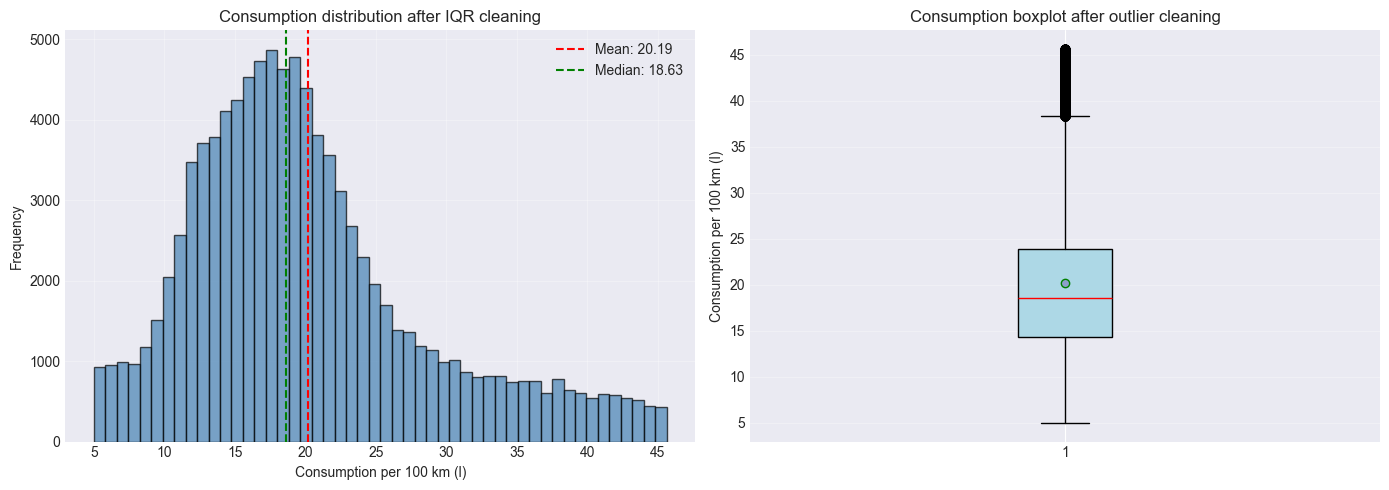

In [8]:
initial_rows = len(df)

# Keep the original statistics for comparison
original_mean = df['Average (l/100 km)'].mean()
original_median = df['Average (l/100 km)'].median()
original_std = df['Average (l/100 km)'].std()

before = len(df)
df = df[df['Speed'] <= 100]
print(f"   Speed <= 100 km/h: removed {before - len(df):,} rows")

before = len(df)
df = df[df['Distance (km)'] >= 1]
print(f"   Distance >= 1 km: removed {before - len(df):,} rows")

before = len(df)
df = df[df['Total time (hours)'] <= 16]
print(f"   Time <= 16 hours: removed {before - len(df):,} rows")

before = len(df)
df = df[df['Average (l/100 km)'] >= 5]
print(f"   Fuel consumption >= 5 l/100 km: removed {before - len(df):,} rows")

# IQR for consumption per 100 km
q1 = df['Average (l/100 km)'].quantile(0.25)
q3 = df['Average (l/100 km)'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"   Lower bound (Q1 - 1.5*IQR): {lower_bound:.2f}")
print(f"   Upper bound (Q3 + 1.5*IQR): {upper_bound:.2f}")

before = len(df)
df = df[(df['Average (l/100 km)'] >= lower_bound) & (df['Average (l/100 km)'] <= upper_bound)]
print(f"   IQR: removed {before - len(df):,} rows")

# Remove Rare Buses
bus_counts = df['Bus ID'].value_counts()
buses_to_keep = bus_counts[bus_counts >= 10].index
before = len(df)
df = df[df['Bus ID'].isin(buses_to_keep)]
print(f"   Buses with at least 10 trips: removed {before - len(df):,} rows")

# Cleaning Summary
final_mean = df['Average (l/100 km)'].mean()
final_median = df['Average (l/100 km)'].median()
final_std = df['Average (l/100 km)'].std()

print(f"\nConsumption per 100 km after cleaning:")
print(f"   Mean: {final_mean:.2f} (was {original_mean:.2f})")
print(f"   Median: {final_median:.2f} (was {original_median:.2f})")
print(f"   Standard deviation: {final_std:.2f} (was {original_std:.2f})")
print(f"   Min: {df['Average (l/100 km)'].min():.2f}")
print(f"   Max: {df['Average (l/100 km)'].max():.2f}")

print(f"\n Overall summary:")
print(f"   Initial size: {initial_rows:,} rows")
print(f"   Final size: {len(df):,} rows")
print(f"   Removed: {initial_rows - len(df):,} rows ({((initial_rows - len(df))/initial_rows*100):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['Average (l/100 km)'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].axvline(df['Average (l/100 km)'].mean(), color='red', linestyle='--', 
                label=f'Mean: {df["Average (l/100 km)"].mean():.2f}')
axes[0].axvline(df['Average (l/100 km)'].median(), color='green', linestyle='--', 
                label=f'Median: {df["Average (l/100 km)"].median():.2f}')
axes[0].set_xlabel('Consumption per 100 km (l)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Consumption distribution after IQR cleaning')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Boxplot
box = axes[1].boxplot(df['Average (l/100 km)'], vert=True, patch_artist=True, showmeans=True)
box['boxes'][0].set_facecolor('lightblue')
box['medians'][0].set_color('red')
box['means'][0].set_marker('o')
box['means'][0].set_markeredgecolor('green')
axes[1].set_ylabel('Consumption per 100 km (l)')
axes[1].set_title('Consumption boxplot after outlier cleaning')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 1.9 Add Seasonal and Time-of-Day Features


In [9]:
# Winter months: December, January, February
df['is winter'] = df['Month'].isin([12, 1, 2]).astype(int)

# Summer months: June, July, August
df['is summer'] = df['Month'].isin([6, 7, 8]).astype(int)

# Night hours
df['is night'] = df['Hour'].isin([23, 0, 1, 2, 3, 4, 5]).astype(int)

# Rush hours: 7-10 in the morning and 17-20 in the evening
df['is rush hour'] = (((df['Hour'] >= 7) & (df['Hour'] <= 10)) | 
                      ((df['Hour'] >= 17) & (df['Hour'] <= 20))).astype(int)

## 1.10 Final DataFrame


In [10]:
columns_to_keep = ['Date', 'Bus ID', 'District',
    'Fuel consumption (l)', 'Distance (km)', 'Average (l/100 km)',
    'Consumption rate (l/100km)', 'Hour', 'Day of the week', 'Month',
    'Month (sin)', 'Month (cos)', 'Weekend', 'Time of day',
    'is winter', 'is summer', 'is night', 'is rush hour']
df = df[columns_to_keep].copy()

print(f"DataFrame size: {len(df):,} rows, {len(df.columns)} columns")
missing_stats = df.isnull().sum()
missing_stats = missing_stats[missing_stats > 0]
print(f"Missing values: {missing_stats if len(missing_stats)>0 else 0}")

print("Final columns:")
print(df.columns.tolist())

DataFrame size: 96,426 rows, 18 columns
Missing values: Consumption rate (l/100km)    25925
dtype: int64
Final columns:
['Date', 'Bus ID', 'District', 'Fuel consumption (l)', 'Distance (km)', 'Average (l/100 km)', 'Consumption rate (l/100km)', 'Hour', 'Day of the week', 'Month', 'Month (sin)', 'Month (cos)', 'Weekend', 'Time of day', 'is winter', 'is summer', 'is night', 'is rush hour']


In [11]:
annual_mileage = df['Distance (km)'].sum()

print(f'Annual route mileage: {annual_mileage:,.0f} km')

Annual route mileage: 10,576,304 km


# Stage 2: EDA and Descriptive Statistics

## 2.1 Target Summary Statistics


In [12]:
target = 'Average (l/100 km)'
print(f"\n Descriptive statistics for {target}:")
stats = df[target].describe()
print(stats.round(2))


 Descriptive statistics for Average (l/100 km):
count    96426.00
mean        20.19
std          8.47
min          5.00
25%         14.34
50%         18.63
75%         23.93
max         45.64
Name: Average (l/100 km), dtype: float64


## 2.2 Consumption Histogram and Boxplot


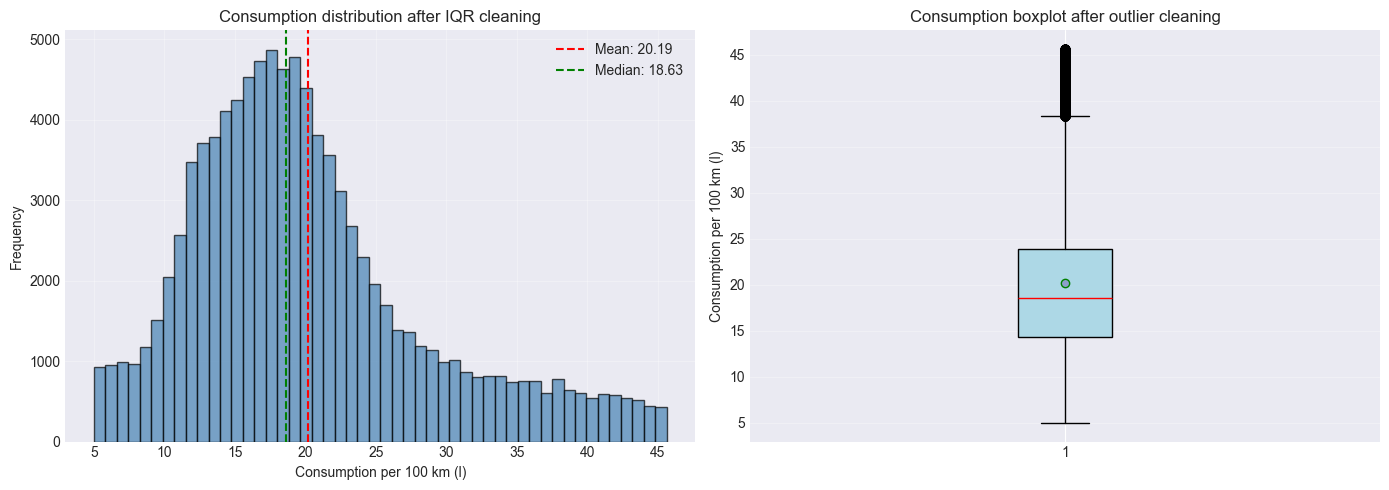

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['Average (l/100 km)'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].axvline(df['Average (l/100 km)'].mean(), color='red', linestyle='--', 
                label=f'Mean: {df["Average (l/100 km)"].mean():.2f}')
axes[0].axvline(df['Average (l/100 km)'].median(), color='green', linestyle='--', 
                label=f'Median: {df["Average (l/100 km)"].median():.2f}')
axes[0].set_xlabel('Consumption per 100 km (l)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Consumption distribution after IQR cleaning')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Boxplot
box = axes[1].boxplot(df['Average (l/100 km)'], vert=True, patch_artist=True, showmeans=True)
box['boxes'][0].set_facecolor('lightblue')
box['medians'][0].set_color('red')
box['means'][0].set_marker('o')
box['means'][0].set_markeredgecolor('green')
axes[1].set_ylabel('Consumption per 100 km (l)')
axes[1].set_title('Consumption boxplot after outlier cleaning')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 2.3 Distribution by District


DISTRICT STATISTICS
                   Average consumption  Median  Std deviation  Trip count
District                                                                 
Пикалево                         24.72   23.83           8.77        2791
Волхов                           23.27   20.79          10.89       18605
Тихвин                           22.36   21.57           8.18       19225
Лодейное поле                    21.67   19.73           8.98        3062
Сосново-Приозерск                18.91   17.79           5.57       13803
Всеволожск                       17.66   15.91           7.17       23891
Сосновый Бор                     17.65   16.97           6.87       15049


C:\Users\User\AppData\Local\Temp\ipykernel_18904\2830525922.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


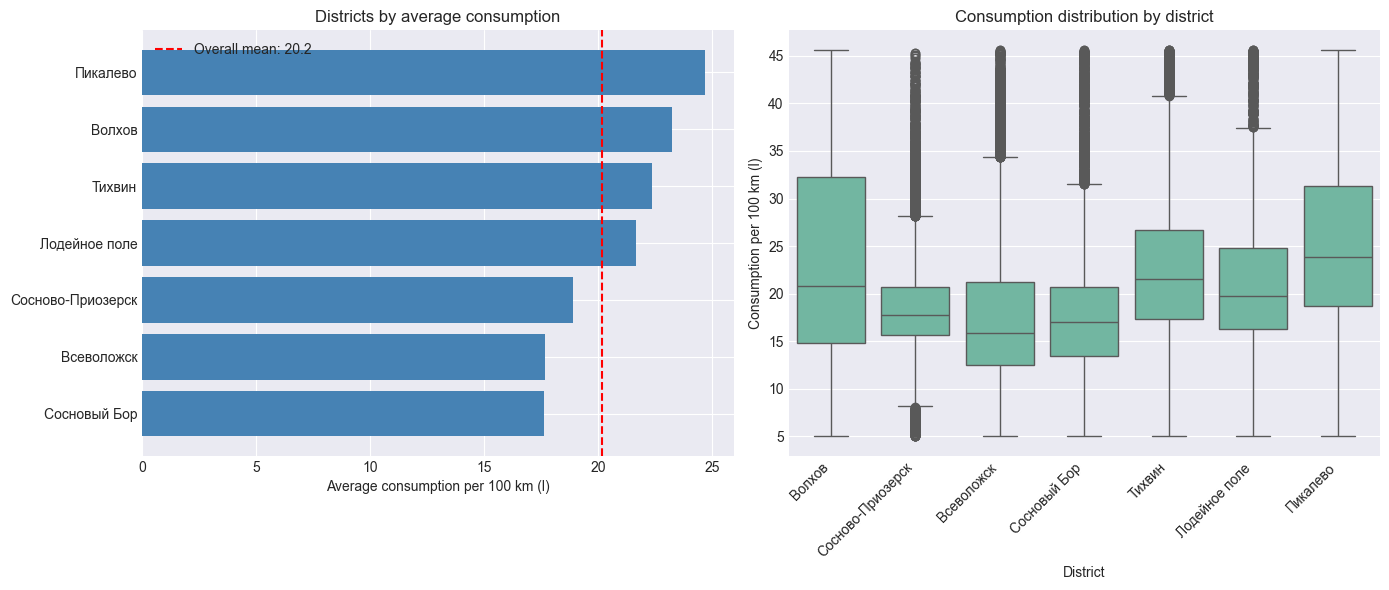

In [14]:
# District statistics
rayon_stats = df.groupby('District').agg({
    target: ['mean', 'median', 'std', 'count']
}).round(2)

rayon_stats.columns = ['Average consumption', 'Median', 'Std deviation', 'Trip count']
rayon_stats = rayon_stats.sort_values('Average consumption', ascending=False)

print("=" * 60)
print("DISTRICT STATISTICS")
print("=" * 60)
print(rayon_stats.to_string())

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Average consumption bar chart
top_rayons = rayon_stats.head(10)
axes[0].barh(top_rayons.index, top_rayons['Average consumption'], color='steelblue')
axes[0].axvline(df[target].mean(), color='red', linestyle='--', 
                label=f'Overall mean: {df[target].mean():.1f}')
axes[0].set_xlabel('Average consumption per 100 km (l)')
axes[0].set_title('Districts by average consumption')
axes[0].legend()
axes[0].invert_yaxis()

# District boxplot
top7_rayons = rayon_stats.head(7).index
df_top7 = df[df['District'].isin(top7_rayons)]
sns.boxplot(data=df_top7, x='District', y=target, ax=axes[1])
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_ylabel('Consumption per 100 km (l)')
axes[1].set_title('Consumption distribution by district')

plt.tight_layout()
plt.show()

## 2.4 Time-of-Day and Seasonality Effects


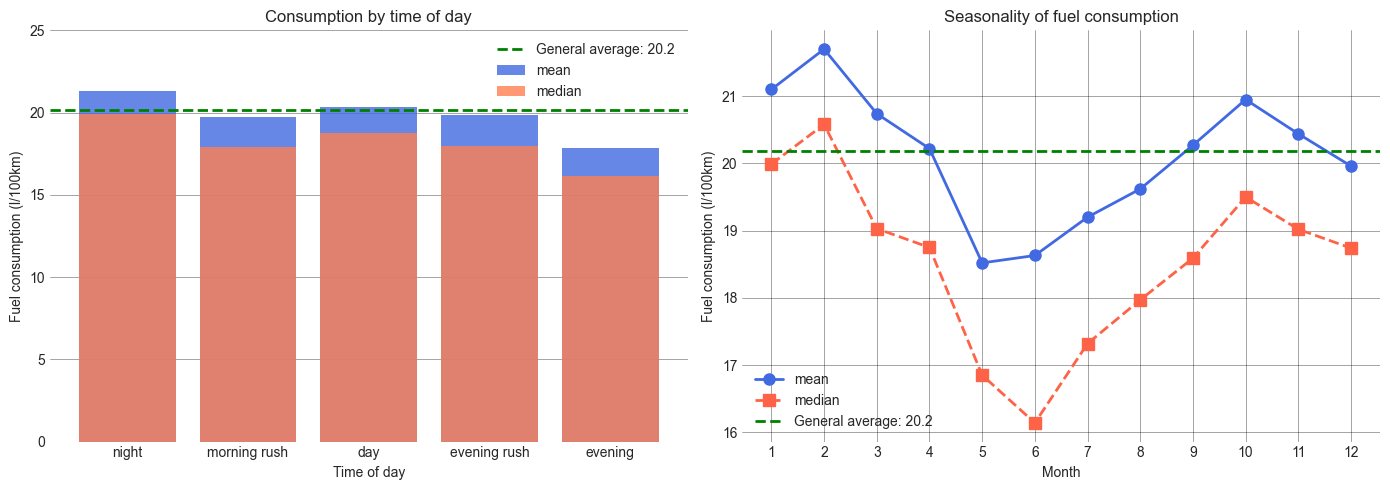


Time-of-day statistics:
               mean  median
Time of day                
night         21.31   19.94
morning rush  19.71   17.94
day           20.35   18.78
evening rush  19.83   17.95
evening       17.84   16.16

Monthly statistics:
        mean  median
Month               
1      21.10   19.99
2      21.70   20.58
3      20.74   19.03
4      20.22   18.75
5      18.52   16.85
6      18.63   16.14
7      19.20   17.32
8      19.62   17.97
9      20.27   18.59
10     20.95   19.50
11     20.44   19.02
12     19.96   18.74


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. By time of day
time_stats = df.groupby('Time of day')[target].agg(['mean', 'median']).round(2)
order = ['night', 'morning rush', 'day', 'evening rush', 'evening']
time_stats = time_stats.reindex(order)

# Set a white background for the first chart
axes[0].set_facecolor('white')

# Draw bars with muted blue for the mean and pink for the median
bars = axes[0].bar(time_stats.index, time_stats['mean'], color='royalblue', alpha=0.8, label='mean')
bars = axes[0].bar(time_stats.index, time_stats['median'], color='coral', alpha=0.8, label='median')
axes[0].axhline(df[target].mean(), color='green', linestyle='--', linewidth=2,
                label=f'General average: {df[target].mean():.1f}')
axes[0].set_xlabel('Time of day')
axes[0].set_ylabel('Fuel consumption (l/100km)')
axes[0].set_title('Consumption by time of day')
axes[0].legend()
axes[0].grid(True, alpha=0.5, color='black', linestyle='-', linewidth=0.5, axis='y')

# Set the upper y-axis limit to 25
axes[0].set_ylim(0, 25)

# 2. By month (seasonality), with a white background and black grid
month_stats = df.groupby('Month')[target].agg(['mean', 'median']).round(2)

# Set a white background and black grid for the second chart
axes[1].set_facecolor('white')
axes[1].plot(month_stats.index, month_stats['mean'], 'o-', linewidth=2, markersize=8, label='mean', color='royalblue')
axes[1].plot(month_stats.index, month_stats['median'], 's--', linewidth=2, markersize=8, label='median', color='tomato')
axes[1].axhline(df[target].mean(), color='green', linestyle='--', linewidth=2,
                label=f'General average: {df[target].mean():.1f}')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Fuel consumption (l/100km)')
axes[1].set_title('Seasonality of fuel consumption')
axes[1].set_xticks(range(1, 13))
axes[1].legend()
axes[1].grid(True, alpha=0.5, color='black', linestyle='-', linewidth=0.5)

plt.tight_layout()


# You can also save other formats:
# plt.savefig('fuel_consumption_by_time_and_season.pdf', dpi=300, bbox_inches='tight', facecolor='white')
# plt.savefig('fuel_consumption_by_time_and_season.jpg', dpi=300, bbox_inches='tight', quality=95)

plt.show()

print("\nTime-of-day statistics:")
print(time_stats)
print("\nMonthly statistics:")
print(month_stats)


## 2.5 Feature Correlation


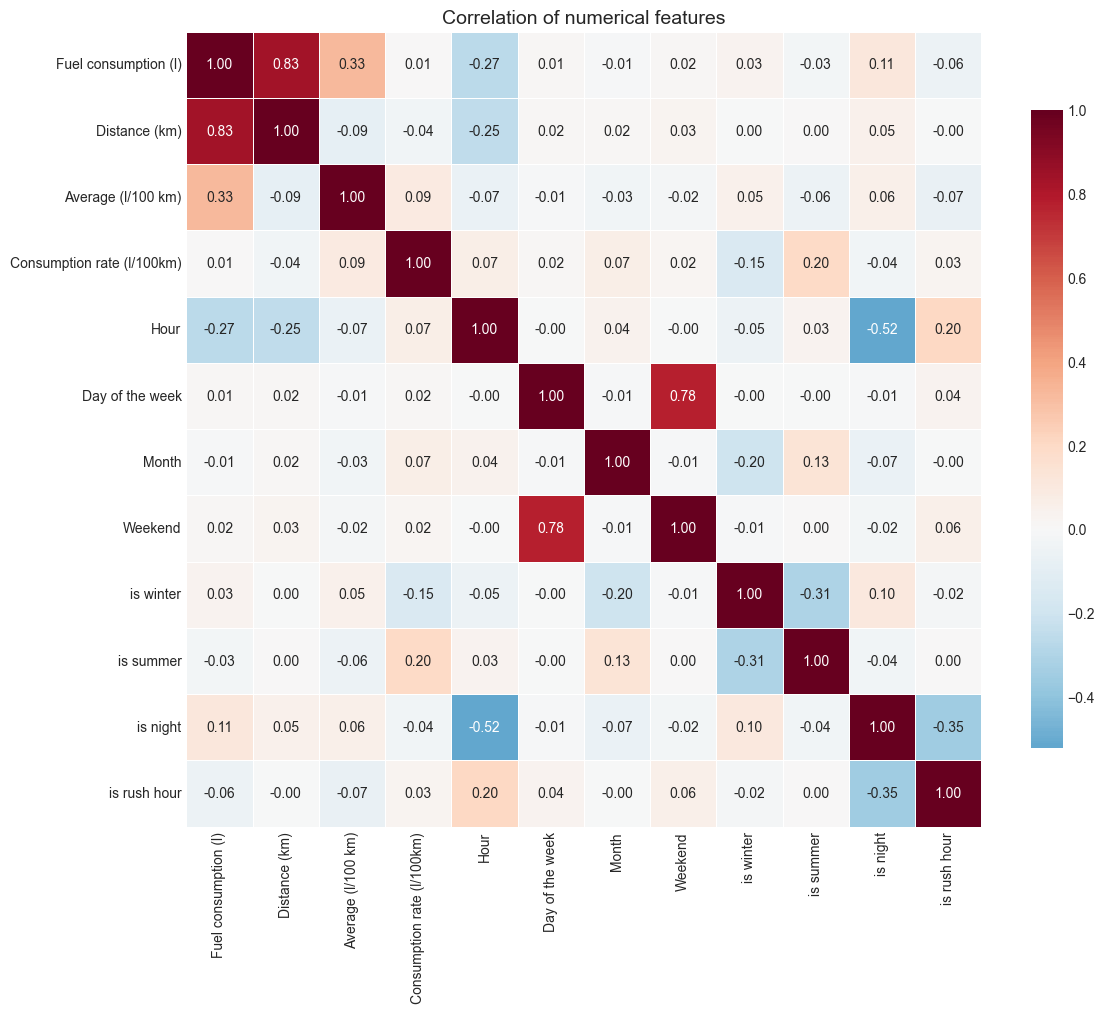

CORRELATION WITH TARGET VARIABLE
Average (l/100 km)            1.000
Fuel consumption (l)          0.327
Consumption rate (l/100km)    0.093
is night                      0.057
is winter                     0.051
Day of the week              -0.012
Weekend                      -0.019
Month                        -0.031
is summer                    -0.062
Hour                         -0.066
is rush hour                 -0.071
Distance (km)                -0.092
Name: Average (l/100 km), dtype: float64


In [16]:
# Select numeric features for correlation
numeric_cols = ['Fuel consumption (l)', 'Distance (km)', 'Average (l/100 km)',
    'Consumption rate (l/100km)', 'Hour', 'Day of the week', 'Month',
    'Weekend', 'is winter', 'is summer', 'is night', 'is rush hour']

# Keep only columns that exist
numeric_cols = [col for col in numeric_cols if col in df.columns]

# Correlation matrix
corr_matrix = df[numeric_cols].corr()

# Visualization - fully populated matrix without a mask
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation of numerical features', fontsize=14)
plt.tight_layout()

# Save the correlation matrix
plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight', facecolor='white')
# Alternative formats:
# plt.savefig('correlation_matrix.pdf', dpi=300, bbox_inches='tight', facecolor='white')
# plt.savefig('correlation_matrix.jpg', dpi=300, bbox_inches='tight', quality=95)

plt.show()

# Top correlations with the target
print("CORRELATION WITH TARGET VARIABLE")
target_corr = corr_matrix[target].sort_values(ascending=False)
print(target_corr.round(3))

## 2.6 Full Descriptive Statistics for All Variables


In [17]:
# Select all numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Create the statistics table
stats_table = pd.DataFrame(index=numeric_cols)

# Basic statistics
stats_table['count'] = df[numeric_cols].count()
stats_table['mean'] = df[numeric_cols].mean()
stats_table['std'] = df[numeric_cols].std()
stats_table['min'] = df[numeric_cols].min()
stats_table['25%'] = df[numeric_cols].quantile(0.25)
stats_table['50%'] = df[numeric_cols].median()
stats_table['75%'] = df[numeric_cols].quantile(0.75)
stats_table['max'] = df[numeric_cols].max()

# Additional useful metrics
stats_table['skew'] = df[numeric_cols].skew()  # skewness
stats_table['kurtosis'] = df[numeric_cols].kurtosis()  # kurtosis

# IQR (interquartile range)
stats_table['IQR'] = stats_table['75%'] - stats_table['25%']

# Coefficient of variation (CV = std/mean * 100%), showing dispersion relative to the mean
stats_table['CV_%'] = (stats_table['std'] / stats_table['mean']) * 100

stats_table = stats_table.round({
    'mean': 2,
    'std': 2,
    'min': 2,
    '25%': 2,
    '50%': 2,
    '75%': 2,
    'max': 2,
    'skew': 3,
    'kurtosis': 3,
    'IQR': 2,
    'CV_%': 1
})

# Display the table
print("COMPLETE STATISTICS ON NUMERIC VARIABLES:")
print(stats_table.to_string())


COMPLETE STATISTICS ON NUMERIC VARIABLES:
                            count    mean    std   min    25%    50%     75%     max   skew  kurtosis     IQR    CV_%
Fuel consumption (l)        96426   21.40  19.61  0.06   7.02  16.61   28.42  287.79  2.012     6.824   21.40    91.6
Distance (km)               96426  109.68  97.46  1.00  41.86  83.18  144.52  774.06  1.862     4.169  102.66    88.9
Average (l/100 km)          96426   20.19   8.47  5.00  14.34  18.63   23.93   45.64  0.910     0.515    9.59    42.0
Consumption rate (l/100km)  70501   19.07   7.66  9.08  10.73  19.32   20.57   42.94  0.917     0.539    9.84    40.2
Hour                        96426   10.77   5.51  0.00   6.00  10.00   15.00   23.00  0.347    -0.869    9.00    51.1
Day of the week             96426    2.89   1.97  0.00   1.00   3.00    5.00    6.00  0.068    -1.201    4.00    68.3
Month                       96426    6.19   3.48  1.00   3.00   6.00    9.00   12.00  0.179    -1.242    6.00    56.2
Month (sin)   

## 2.7 Categorical Variable Statistics


In [18]:
# Select categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

for col in categorical_cols:
    print(f"\n {col}:")
    print("-" * 40)
    value_counts = df[col].value_counts()
    print(f"   Unique values: {df[col].nunique()}")
    print(f"   Most frequent values:")
    for val, cnt in value_counts.head(5).items():
        pct = cnt / len(df) * 100
        print(f"      {val}: {cnt:,} ({pct:.1f}%)")
    
    # Missing values
    missing = df[col].isna().sum()
    if missing > 0:
        print(f"   Missing values: {missing:,} ({missing/len(df)*100:.1f}%)")


 Date:
----------------------------------------
   Unique values: 366
   Most frequent values:
      2026-04-23: 497 (0.5%)
      2026-04-02: 473 (0.5%)
      2026-04-15: 471 (0.5%)
      2026-04-13: 461 (0.5%)
      2026-04-07: 453 (0.5%)

 Bus ID:
----------------------------------------
   Unique values: 177
   Most frequent values:
      Т612УА198: 2,267 (2.4%)
      В411ВС198: 1,712 (1.8%)
      У358НК778: 1,707 (1.8%)
      М611РР198: 1,632 (1.7%)
      В287КР178: 1,587 (1.6%)

 District:
----------------------------------------
   Unique values: 7
   Most frequent values:
      Всеволожск: 23,891 (24.8%)
      Тихвин: 19,225 (19.9%)
      Волхов: 18,605 (19.3%)
      Сосновый Бор: 15,049 (15.6%)
      Сосново-Приозерск: 13,803 (14.3%)

 Time of day:
----------------------------------------
   Unique values: 5
   Most frequent values:
      day: 36,937 (38.3%)
      night: 21,888 (22.7%)
      morning rush: 21,417 (22.2%)
      evening rush: 8,946 (9.3%)
      evening: 7,238 (7.

C:\Users\User\AppData\Local\Temp\ipykernel_18904\22745464.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


# Stage 3: Feature Engineering

## 3.1 Encode Categorical Features


In [19]:
from sklearn.preprocessing import LabelEncoder

# 1. Encode bus ID with LabelEncoder
le_bus = LabelEncoder()
df['Bus code'] = le_bus.fit_transform(df['Bus ID'])
print(f" bus_code: {df['Bus code'].nunique()} unique values")

# 2. Encode district with LabelEncoder
le_rayon = LabelEncoder()
df['District code'] = le_rayon.fit_transform(df['District'])
print(f" rayon_code: {df['District code'].nunique()} unique values")

# 3. Encode the existing time-of-day category
df['Time of day code'] = df['Time of day'].map({
    'night': 0,
    'morning rush': 1,
    'day': 2,
    'evening rush': 3,
    'evening': 4
})

print(f" time_of_day_code: {df['Time of day code'].nunique()} unique values")

 bus_code: 177 unique values
 rayon_code: 7 unique values
 time_of_day_code: 5 unique values


## 3.3 Final Feature Set for the Model


In [20]:
features = [
    # Core features
    'Distance (km)',           # from the contract
    'Hour',                     # from the schedule
    'Day of the week',             # from the schedule
    'Weekend',                # from the schedule
    
    # Seasonal features from the date
    'Month (sin)',             # cyclical month
    'Month (cos)',           # cyclical month
    
    # Categorical features from reference tables
    'Bus code',                # bus ID
    'District code',              # district
    
    # Rate from the reference table
    'Consumption rate (l/100km)',
    
    # Seasonal and time flags
    'is winter',
    'is summer',
    'is night',
    'is rush hour'
]

# Check that all features exist in the data

print(f"\nUsing {len(features)} features:")
for i, f in enumerate(features, 1):
    print(f"   {i}. {f}")

# Target variable
target = 'Average (l/100 km)'
print(f"\nTarget variable: {target}")


Using 13 features:
   1. Distance (km)
   2. Hour
   3. Day of the week
   4. Weekend
   5. Month (sin)
   6. Month (cos)
   7. Bus code
   8. District code
   9. Consumption rate (l/100km)
   10. is winter
   11. is summer
   12. is night
   13. is rush hour

Target variable: Average (l/100 km)


## 3.4 TRAIN/TEST SPLIT (80/20)


In [21]:
from sklearn.model_selection import train_test_split

# Select data
X = df[features].copy()
y = df[target].copy()

# Remove rows with missing values, if any
before = len(X)
X = X.dropna()
y = y[X.index]
print(f"Removed rows with missing values: {before - len(X)}")

# Split into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,      # ← 20% for testing
    random_state=42, 
    shuffle=True
)

print(f"\nSplit sizes:")
print(f"   Train: {len(X_train):,} rows ({len(X_train)/len(X)*100:.1f}%)")
print(f"   Test: {len(X_test):,} rows ({len(X_test)/len(X)*100:.1f}%)")

Removed rows with missing values: 25925

Split sizes:
   Train: 56,400 rows (80.0%)
   Test: 14,101 rows (20.0%)


# Stage 4: Model Building

## 4.1 Modeling Imports


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from time import time

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Sklearn models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

# XGBoost
import xgboost as xgb
from xgboost import XGBRegressor

# Settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")
pd.set_option('display.max_columns', None)

## 4.2 Check Prepared Data Loading


In [23]:
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {len(y_train)}")
print(f"y_test: {len(y_test)}")

# Check the target variable
print(f"\nTarget statistics (y_test):")
print(y_test.describe().round(2))

X_train: (56400, 13)
X_test: (14101, 13)
y_train: 56400
y_test: 14101

Target statistics (y_test):
count    14101.00
mean        20.27
std          8.59
min          5.01
25%         14.36
50%         18.58
75%         24.15
max         45.64
Name: Average (l/100 km), dtype: float64


## 4.3 BASELINE: Simple Rate Baseline


In [24]:
# Prediction equals the consumption rate
y_pred_norm = X_test['Consumption rate (l/100km)']

mae_norm = mean_absolute_error(y_test, y_pred_norm)
mape_norm = mean_absolute_percentage_error(y_test, y_pred_norm) * 100
r2_norm = r2_score(y_test, y_pred_norm)

print(f"MAE: {mae_norm:.2f} l/100 km")
print(f"MAPE: {mape_norm:.1f}%")
print(f"R²: {r2_norm:.3f}")

baseline_results = {
    'Model': 'Baseline (rate)',
    'MAE': mae_norm,
    'MAPE': mape_norm,
    'R²': r2_norm,
    'Training time (sec)': 0
}

MAE: 8.14 l/100 km
MAPE: 46.6%
R²: -0.675


## 4.4 Training and Evaluation Function


In [25]:
def train_and_evaluate(model, model_name, X_train, X_test, y_train, y_test):
    """Train the model and return metrics and training time"""
    start_time = time()
    model.fit(X_train, y_train)
    train_time = time() - start_time
    
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)
    
    print(f"\n{model_name}:")
    print(f"   MAE: {mae:.2f} l/100 km")
    print(f"   MAPE: {mape:.1f}%")
    print(f"   R²: {r2:.3f}")
    print(f"   Training time: {train_time:.2f} sec")
    
    return {
        'Model': model_name,
        'MAE': mae,
        'MAPE': mape,
        'R²': r2,
        'Training time (sec)': train_time
    }, model, y_pred

## 4.5 Model 1: LINEAR REGRESSION


In [26]:
lr = LinearRegression()
lr_result, lr_model, lr_pred = train_and_evaluate(
    lr, 'Linear Regression', X_train, X_test, y_train, y_test
)


Linear Regression:
   MAE: 6.41 l/100 km
   MAPE: 38.8%
   R²: 0.036
   Training time: 0.04 sec


## 4.6 Model 2: RIDGE REGRESSION (L2 regularization)


In [27]:
ridge = Ridge(alpha=1.0)
ridge_result, ridge_model, ridge_pred = train_and_evaluate(
    ridge, 'Ridge', X_train, X_test, y_train, y_test
)


Ridge:
   MAE: 6.41 l/100 km
   MAPE: 38.8%
   R²: 0.036
   Training time: 0.01 sec


## 4.7 Model 3: LASSO REGRESSION


In [28]:
lasso = Lasso(alpha=0.01)
lasso_result, lasso_model, lasso_pred = train_and_evaluate(
    lasso, 'Lasso', X_train, X_test, y_train, y_test
)


Lasso:
   MAE: 6.41 l/100 km
   MAPE: 38.8%
   R²: 0.036
   Training time: 0.07 sec


## 4.8 Model 4: DECISION TREE


In [29]:
dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt_result, dt_model, dt_pred = train_and_evaluate(
    dt, 'Decision Tree', X_train, X_test, y_train, y_test
)


Decision Tree:
   MAE: 4.45 l/100 km
   MAPE: 27.4%
   R²: 0.473
   Training time: 0.18 sec


## 4.9 Model 5: RANDOM FOREST


In [30]:
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=10, 
    random_state=42, 
    n_jobs=-1
)
rf_result, rf_model, rf_pred = train_and_evaluate(
    rf, 'Random Forest', X_train, X_test, y_train, y_test
)


Random Forest:
   MAE: 4.29 l/100 km
   MAPE: 26.6%
   R²: 0.524
   Training time: 0.86 sec


## 4.10 Model 6: GRADIENT BOOSTING


In [31]:
gb = GradientBoostingRegressor(
    n_estimators=100, 
    max_depth=5, 
    learning_rate=0.1, 
    random_state=42
)
gb_result, gb_model, gb_pred = train_and_evaluate(
    gb, 'Gradient Boosting', X_train, X_test, y_train, y_test
)


Gradient Boosting:
   MAE: 4.38 l/100 km
   MAPE: 27.0%
   R²: 0.504
   Training time: 8.24 sec


## 4.11 Model 7: XGBOOST


In [32]:
xgb = XGBRegressor(
    n_estimators=100, 
    max_depth=6, 
    learning_rate=0.1, 
    random_state=42, 
    n_jobs=-1
)
xgb_result, xgb_model, xgb_pred = train_and_evaluate(
    xgb, 'XGBoost', X_train, X_test, y_train, y_test
)


XGBoost:
   MAE: 4.08 l/100 km
   MAPE: 25.2%
   R²: 0.563
   Training time: 0.47 sec


## 4.12 Model 8: XGBOOST with GridSearch


In [33]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

# Base model
xgb_base = XGBRegressor(random_state=42, n_jobs=-1)

# Parameter grid
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [8, 10],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0]
}

# GridSearch
xgb_grid = GridSearchCV(
    xgb_base, 
    param_grid, 
    cv=5, 
    scoring='r2', 
    verbose=1, 
    n_jobs=-1
)

# Train
xgb_grid.fit(X_train, y_train)

# Best parameters
print("Best parameters:", xgb_grid.best_params_)
print("Best cross-validation R2:", xgb_grid.best_score_)

# Test-set evaluation
xgb_grid_result, xgb_grid_model, xgb_grid_pred = train_and_evaluate(
    xgb_grid, 'XGBoost GridSearch', X_train, X_test, y_train, y_test
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 10, 'n_estimators': 200, 'subsample': 0.8}
Best cross-validation R2: 0.7664479462872175
Fitting 5 folds for each of 16 candidates, totalling 80 fits

XGBoost GridSearch:
   MAE: 2.53 l/100 km
   MAPE: 15.3%
   R²: 0.801
   Training time: 9.93 sec


## 4.13 Model 9: LightGBM


In [34]:
import lightgbm as lgb
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    max_depth=10,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lightgbm_result, lightgbm_model, lightgbm_pred = train_and_evaluate(
    lgb_model, 'LightGBM', X_train, X_test, y_train, y_test
)


LightGBM:
   MAE: 4.00 l/100 km
   MAPE: 24.8%
   R²: 0.579
   Training time: 0.43 sec


## 4.14 Model 10: CatBoost


In [35]:
import catboost as cb
cat_model = cb.CatBoostRegressor(
    iterations=300,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False
)
cat_result, cat_model, cat_pred = train_and_evaluate(
    cat_model, 'CatBoost', X_train, X_test, y_train, y_test
)


CatBoost:
   MAE: 4.15 l/100 km
   MAPE: 25.7%
   R²: 0.553
   Training time: 1.75 sec


## 4.15 Model 11: Extra Trees


In [36]:
from sklearn.ensemble import ExtraTreesRegressor
et_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
et_result, et_model, et_pred = train_and_evaluate(
    et_model, 'Extra Trees', X_train, X_test, y_train, y_test
)


Extra Trees:
   MAE: 3.08 l/100 km
   MAPE: 19.1%
   R²: 0.731
   Training time: 1.00 sec


## 4.16 Model 12: HistGradientBoosting


In [37]:
from sklearn.ensemble import HistGradientBoostingRegressor
hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    max_depth=10,
    learning_rate=0.05,
    random_state=42
)
hgb_result, hgb_model, hgb_pred = train_and_evaluate(
    hgb_model, 'HistGradientBoosting', X_train, X_test, y_train, y_test
)


HistGradientBoosting:
   MAE: 4.15 l/100 km
   MAPE: 25.8%
   R²: 0.549
   Training time: 2.06 sec


## 4.17 Model 13: SVM LinearSVR


In [38]:
from sklearn.svm import LinearSVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm_model = make_pipeline(
    StandardScaler(),
    LinearSVR(
        C=1.0,
        epsilon=0.2,
        random_state=42,
        max_iter=10000,
    ),
)

# Correct order: model first, then model name
svm_result, svm_model, svm_pred = train_and_evaluate(
    svm_model,  # <-- model, not a string
    'SVM LinearSVR',  # <-- name
    X_train, X_test, y_train, y_test
)


SVM LinearSVR:
   MAE: 6.26 l/100 km
   MAPE: 35.0%
   R²: -0.008
   Training time: 0.13 sec


## 4.18 Model 14: SVM LinearSVR


In [39]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ann_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        solver='adam',
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=250,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=42,
    ),
)

ann_result, ann_model, ann_pred = train_and_evaluate(
    ann_model,  # model first
    'ANN MLPRegressor',  # then model name
    X_train, X_test, y_train, y_test
)


ANN MLPRegressor:
   MAE: 4.31 l/100 km
   MAPE: 26.0%
   R²: 0.516
   Training time: 121.94 sec


## 4.19 Compare All Models


In [40]:
all_results = pd.DataFrame([
    baseline_results,
    lr_result,
    ridge_result,
    lasso_result,
    dt_result,
    rf_result,
    gb_result,
    xgb_result,
    xgb_grid_result,
    lightgbm_result,
    cat_result,
    et_result,
    hgb_result,
    svm_result,
    ann_result
])

# Sort by MAE
all_results = all_results.sort_values('MAE').round({
    'MAE': 2,
    'MAPE': 1,
    'R²': 3,
    'Training time (sec)': 2
})

print("\nRESULTS FOR ALL MODELS:")
print("=" * 80)
print(all_results.to_string(index=False))



RESULTS FOR ALL MODELS:
               Model  MAE  MAPE     R²  Training time (sec)
  XGBoost GridSearch 2.53  15.3  0.801                 9.93
         Extra Trees 3.08  19.1  0.731                 1.00
            LightGBM 4.00  24.8  0.579                 0.43
             XGBoost 4.08  25.2  0.563                 0.47
            CatBoost 4.15  25.7  0.553                 1.75
HistGradientBoosting 4.15  25.8  0.549                 2.06
       Random Forest 4.29  26.6  0.524                 0.86
    ANN MLPRegressor 4.31  26.0  0.516               121.94
   Gradient Boosting 4.38  27.0  0.504                 8.24
       Decision Tree 4.45  27.4  0.473                 0.18
       SVM LinearSVR 6.26  35.0 -0.008                 0.13
               Lasso 6.41  38.8  0.036                 0.07
               Ridge 6.41  38.8  0.036                 0.01
   Linear Regression 6.41  38.8  0.036                 0.04
     Baseline (rate) 8.14  46.6 -0.675                 0.00


## 4.20 Feature Importance for the Best Model



TOP-10 IMPORTANT FEATURES:
                   Feature  Importance
             District code    0.201306
                  Bus code    0.145067
Consumption rate (l/100km)    0.114417
                  is night    0.087783
                 is winter    0.080662
                 is summer    0.079077
               Month (sin)    0.066485
               Month (cos)    0.057352
                      Hour    0.046094
             Distance (km)    0.045873


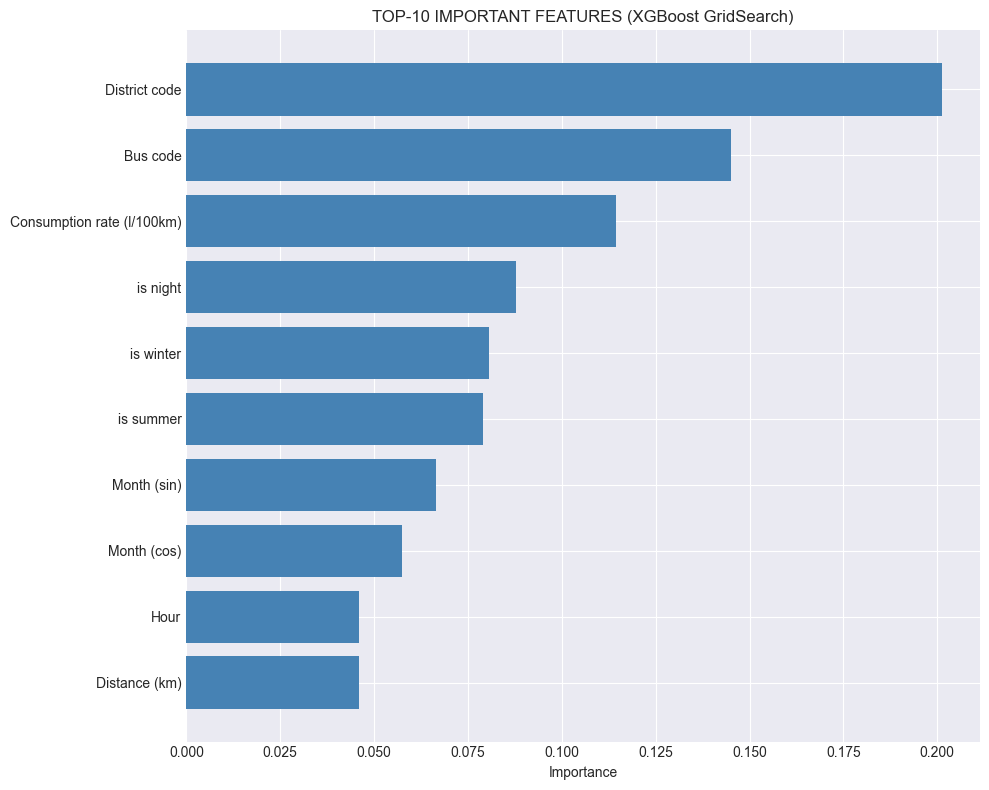

In [41]:
best_model = xgb_grid.best_estimator_
best_model_name = 'XGBoost GridSearch'

# Get feature importance
if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    feature_names = X_train.columns
elif hasattr(best_model, 'coef_'):
    importances = np.abs(best_model.coef_)
    feature_names = X_train.columns
else:
    importances = None

if importances is not None:
    feature_importance = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values('Importance', ascending=False)
    
    print("\nTOP-10 IMPORTANT FEATURES:")
    print(feature_importance.head(10).to_string(index=False))
    
    # Visualization
    plt.figure(figsize=(10, 8))
    top_features = feature_importance.head(10)
    plt.barh(top_features['Feature'], top_features['Importance'], color='steelblue')
    plt.xlabel('Importance')
    plt.title(f'TOP-10 IMPORTANT FEATURES ({best_model_name})')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

## 4.21 Error Analysis for the Best Model


In [42]:
# Use the best model (XGBoost GridSearch)
best_model = xgb_grid.best_estimator_
best_model_name = 'XGBoost GridSearch'

# Get predictions from the best model
best_pred = best_model.predict(X_test)
errors = y_test - best_pred
abs_errors = np.abs(errors)

# Error statistics
print(f"\nError statistics (actual minus predicted):")
print(f"   Mean error (bias): {errors.mean():.3f} l/100 km")
print(f"   Median error: {errors.median():.3f} l/100 km")
print(f"   Standard deviation: {errors.std():.3f}")
print(f"   75th percentile |error|: {abs_errors.quantile(0.75):.3f}")
print(f"   90th percentile |error|: {abs_errors.quantile(0.90):.3f}")

# Create df_test for visualization
df_test = X_test.copy()
df_test['real'] = y_test.values
df_test['pred'] = best_pred
df_test['error'] = errors
df_test['abs_error'] = abs_errors

# Analyze by consumption range
print(f"\nErrors by actual consumption range:")

# Bin actual consumption
bins = [0, 15, 20, 25, 30, 40, 100]
labels = ['<15', '15-20', '20-25', '25-30', '30-40', '>40']
df_test['range'] = pd.cut(df_test['real'], bins=bins, labels=labels)

range_stats = df_test.groupby('range', observed=True).agg({
    'real': 'count',
    'error': 'mean',
    'abs_error': 'mean'
}).round(2)
range_stats.columns = ['Count', 'Mean error', 'MAE']
print(range_stats.to_string())


Error statistics (actual minus predicted):
   Mean error (bias): 0.028 l/100 km
   Median error: -0.072 l/100 km
   Standard deviation: 3.828
   75th percentile |error|: 3.234
   90th percentile |error|: 5.856

Errors by actual consumption range:
       Count  Mean error   MAE
range                         
<15     4001       -2.43  2.74
15-20   4213       -0.47  1.63
20-25   2692        0.92  2.11
25-30   1192        2.29  3.14
30-40   1432        2.68  3.66
>40      571        5.35  5.47


## 4.22 Best Model Predictions vs Actuals


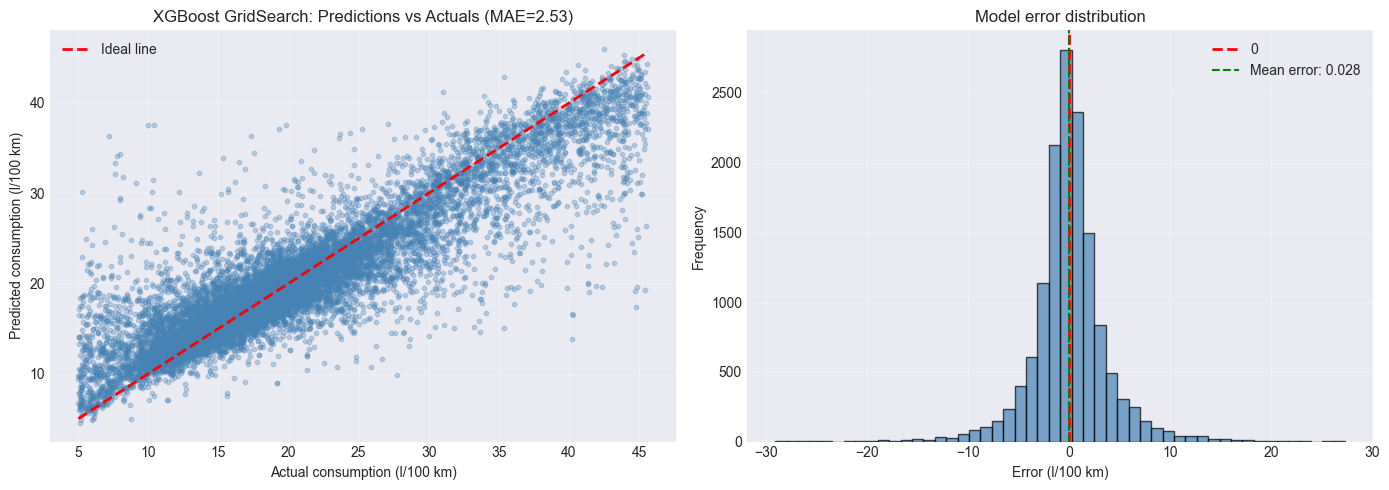


Error statistics XGBoost GridSearch:
   Mean error: 0.028 l/100 km
   Median error: -0.072 l/100 km
   Standard deviation: 3.828
   75th percentile (absolute value): 3.234


In [43]:
# Best model: XGBoost GridSearch
best_model_name = 'XGBoost GridSearch'
best_model_obj = xgb_grid.best_estimator_
best_pred = xgb_grid.predict(X_test)
best_mae = xgb_grid_result["MAE"]


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Predicted vs actual
axes[0].scatter(y_test, best_pred, alpha=0.3, s=10, color='steelblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
            'r--', linewidth=2, label='Ideal line')
axes[0].set_xlabel('Actual consumption (l/100 km)')
axes[0].set_ylabel('Predicted consumption (l/100 km)')
axes[0].set_title(f'{best_model_name}: Predictions vs Actuals (MAE={best_mae:.2f})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Model errors
errors = y_test - best_pred
axes[1].hist(errors, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='0')
axes[1].axvline(errors.mean(), color='green', linestyle='--', 
               label=f'Mean error: {errors.mean():.3f}')
axes[1].set_xlabel('Error (l/100 km)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Model error distribution')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nError statistics {best_model_name}:")
print(f"   Mean error: {errors.mean():.3f} l/100 km")
print(f"   Median error: {errors.median():.3f} l/100 km")
print(f"   Standard deviation: {errors.std():.3f}")
print(f"   75th percentile (absolute value): {np.abs(errors).quantile(0.75):.3f}")

## 4.23 Save the Best Model


In [45]:
import joblib

# Save the XGBoost model
joblib.dump(xgb_grid.best_estimator_, 'best_model.pkl')

# Save encoders
joblib.dump(le_bus, 'le_bus.pkl')
joblib.dump(le_rayon, 'le_rayon.pkl')

['le_rayon.pkl']